# Chapter 7: Variation-based linearization and LQR

This notebook reproduces the chapter's examples.

1. Linearize the spherical pendulum on $S^2$ by hand, check it against finite differences of perturbed nonlinear trajectories, and derive it again symbolically.
2. See why the naive controllability test fails, reduce to the constraint subspace, and design an LQR for the upright pendulum.
3. Linearize the rigid body on $\mathrm{SO}(3)$, hold a nose-up attitude, and compare with an Euler-angle LQR.
4. Track a flip with a finite-horizon LQR, and test the dictionary between the linear state and the geometric errors.
5. Measure where the regulators stop working.

Notation follows the book: $\dot R = R\,\Omega^\wedge$, $\dot q = \omega\times q$, $\delta R = R\,\eta^\wedge$, $\delta q = \xi\times q$.

In [1]:
try:
    import geomech
except ImportError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "geomech==1.1.0"])
    import geomech

import warnings

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy.linalg import solve_continuous_are

print("geomech", geomech.__version__)
E1, E2, E3 = np.eye(3)
I3, Z3 = np.eye(3), np.zeros(3)
GRAV = 9.81


def hat(v):
    x, y, z = v
    return np.array([[0.0, -z, y], [z, 0.0, -x], [-y, x, 0.0]])


def vee(M):
    return np.array([M[2, 1], M[0, 2], M[1, 0]])


def expm_so3(w):
    th = np.linalg.norm(w)
    if th < 1e-12:
        return np.eye(3) + hat(w)
    K = hat(w / th)
    return np.eye(3) + np.sin(th) * K + (1 - np.cos(th)) * K @ K


def log_so3(R):
    th = np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1))
    return vee(R - R.T) / 2 if th < 1e-8 else th / (2 * np.sin(th)) * vee(R - R.T)


def ctrb(A, B):
    return np.hstack([np.linalg.matrix_power(A, k) @ B for k in range(A.shape[0])])

geomech 1.1.0


## 1. The spherical pendulum

A mass $m$ on a rod of length $l$, pushed by a force $F$ on the mass:
$\dot q = \omega\times q$, $\ m l^2\,\dot\omega = -m g l\, q\times e_3 + l\, q\times F$.

The linear state is $s = (\xi, \delta\omega)$ with $A(t)$, $B(t)$ and the constraint matrix $C(t)$ of Proposition 7.1.

In [2]:
m, l = 0.5, 0.8


def s2_f(q, w, F):
    return np.cross(w, q), np.cross(q, F - m * GRAV * E3) / (m * l)


def s2_A(qd, wd, Fd):
    A = np.zeros((6, 6))
    A[:3, :3] = hat(wd)
    A[:3, 3:] = I3 - np.outer(qd, qd)
    A[3:, :3] = hat(Fd - m * GRAV * E3) @ hat(qd) / (m * l)
    return A


def s2_B(qd):
    return np.vstack([np.zeros((3, 3)), hat(qd) / (m * l)])


def s2_C(qd, wd):
    return np.block([[qd, Z3], [np.cross(qd, wd), qd]])


def s2_sim(q0, w0, Ffun, T, **kw):
    rhs = lambda t, x: np.concatenate(s2_f(x[:3], x[3:], Ffun(t, x[:3], x[3:])))
    return solve_ivp(rhs, [0, T], np.r_[q0, w0], rtol=1e-10, atol=1e-12, method="DOP853", dense_output=True, **kw)

### Check against perturbed nonlinear trajectories

Simulate the reference and two neighbors started $\pm\epsilon$ away. Their centered difference, read through $\xi = q_d\times\delta q$, is a finite-difference $s(t)$. It must match the solution of the linear system, with an error that shrinks like $\epsilon^2$.

In [3]:
rng = np.random.default_rng(7)
Fd = lambda t: np.array([0.6 * np.sin(2 * t), 0.4 * np.cos(3 * t), 0.3])
dF = lambda t: np.array([np.cos(t), -0.5, np.sin(2 * t)])
th0 = np.radians(140)
q0 = np.array([np.sin(th0), 0, -np.cos(th0)])
w0 = 1.3 * np.cross(q0, E2) + 0.9 * E2
w0 -= (w0 @ q0) * q0
T = 1.5
ref = s2_sim(q0, w0, lambda t, q, w: Fd(t), T)
xi0, dw0 = np.cross(q0, rng.normal(size=3)), rng.normal(size=3)


def neighbor(e):
    qe = expm_so3(e * xi0) @ q0
    we = w0 + e * dw0
    return s2_sim(qe, we - (we @ qe) * qe, lambda t, q, w: Fd(t) + e * dF(t), T)


for e in (1e-3, 1e-4):
    sp, sm = neighbor(e), neighbor(-e)

    def s_fd(t):
        x, d = ref.sol(t), (sp.sol(t) - sm.sol(t)) / (2 * e)
        return np.r_[np.cross(x[:3], d[:3]), d[3:]]

    lin = solve_ivp(lambda t, s: s2_A(ref.sol(t)[:3], ref.sol(t)[3:], Fd(t)) @ s + s2_B(ref.sol(t)[:3]) @ dF(t),
                    [0, T], s_fd(0), rtol=1e-10, atol=1e-12, method="DOP853", dense_output=True)
    err = max(np.abs(s_fd(t) - lin.sol(t)).max() for t in np.linspace(0, T, 31))
    x = ref.sol(T)
    print(f"eps = {e:.0e}:  max |s_fd - s_lin| = {err:.1e},   |C s_fd(T)| = {np.abs(s2_C(x[:3], x[3:]) @ s_fd(T)).max():.1e}")

eps = 1e-03:  max |s_fd - s_lin| = 4.4e-07,   |C s_fd(T)| = 4.2e-08


eps = 1e-04:  max |s_fd - s_lin| = 5.2e-09,   |C s_fd(T)| = 3.8e-10


### The same linearization from `geomech`

`linearize` returns $M\,\delta\dot x = A\,\delta x + B\,\delta u$ with the same state $(\xi, \delta\omega)$. The dynamic row matches the hand formula entry by entry. The kinematic row is printed as $q q^\top\omega^\wedge$ where we wrote $\omega^\wedge$: the two agree on the constraint subspace and differ off it.

In [4]:
from geomech import S2, Cross, Dot, Scalar, SystemVariables, Vector, check_eom, compute_eom, getScalars, linearize
from geomech.codegen import StateLayout, collect_params, load_module, module_source

half = Scalar("0.5", value=0.5, attr=["Constant"])
m_, g_, l_ = getScalars("m g l", attr=["Constant"])
e3_ = Vector("e3", attr=["Constant"])
q_, F_ = S2("q"), Vector("F")
om_, xi_ = q_.get_tangent_vector(), q_.get_variation_vector()
L = half * m_ * l_ * l_ * Dot(om_, om_) - m_ * g_ * l_ * Dot(q_, e3_)
dW = Dot(Cross(xi_, q_) * l_, F_)                 # a force F at the point l q
V = SystemVariables(vectors=[q_])
eom = compute_eom(L, dW, V)
print("check_eom:", f"{check_eom(L, dW, V, eom, inputs=[F_]):.1e}")
lin_sym = linearize(eom, V, [F_])
print(lin_sym)

layout = StateLayout(V, [F_], collect_params([L, dW], V, [F_]))
mod = load_module(module_source(lin_sym, layout), "pendulum_lin")
p = {"e3": E3, "g": GRAV, "l": l, "m": m}
qd = rng.normal(size=3)
qd /= np.linalg.norm(qd)
wd, Fr = np.cross(qd, rng.normal(size=3)), rng.normal(size=3)
state = layout.pack(q=qd, omega_q=wd)
Mg = mod.M_lin(state, Z3, Fr, p)
Ag, Bg = np.linalg.solve(Mg, mod.A_lin(state, Z3, Fr, p)), np.linalg.solve(Mg, mod.B_lin(state, Z3, Fr, p))
Z = np.linalg.svd(s2_C(qd, wd))[2][2:].T          # basis of the constraint subspace
print("dynamic row, entry by entry :", f"{np.abs(Ag[3:] - s2_A(qd, wd, Fr)[3:]).max():.1e}")
print("B, entry by entry           :", f"{np.abs(Bg - s2_B(qd)).max():.1e}")
print("kinematic row on ker C      :", f"{np.abs((Ag - s2_A(qd, wd, Fr)) @ Z).max():.1e}")
print("kinematic row off ker C     :", f"{np.abs(Ag[:3] - s2_A(qd, wd, Fr)[:3]).max():.2f}")

check_eom: 3.4e-08
LinearizedSystem: M d/dt(dx) = A dx + B du
  states : [\xi_{q}, \delta{\omega_{q}}]
  inputs : [\delta{F}]
  row kin:q
    M[\frac{d}{dt}(\xi_{q})] = I
    A[\xi_{q}] = q*(q)'*Hat(\omega_{q})
    A[\delta{\omega_{q}}] = (I+q*(q)'*(-1))
  row \xi_{q}
    M[\frac{d}{dt}(\delta{\omega_{q}})] = I*m*l*l
    A[\xi_{q}] = (Hat(e3)*Hat(q)*m*g*l*(-1)+Hat(F)*Hat(q)*l)
    B[\delta{F}] = Hat(q)*l
dynamic row, entry by entry : 1.8e-15
B, entry by entry           : 4.4e-16
kinematic row on ker C      : 1.4e-15
kinematic row off ker C     : 0.59


## 2. A state that is not free, and LQR for the upright pendulum

At $q_d = e_3$ the naive rank test gives 4 for a 6-component state. The two missing directions are not states of a pendulum. Reduce to the constraint subspace and the pair is controllable. The Riccati equation on the unreduced pair has no stabilizing solution.

In [5]:
A, B = s2_A(E3, Z3, Z3), s2_B(E3)
Z = np.zeros((6, 4))
Z[0, 0] = Z[1, 1] = Z[3, 2] = Z[4, 3] = 1.0
Ar, Br = Z.T @ A @ Z, Z.T @ B
print("rank, full state   :", np.linalg.matrix_rank(ctrb(A, B)), "of 6")
print("rank, reduced state:", np.linalg.matrix_rank(ctrb(Ar, Br)), "of 4")
try:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        solve_continuous_are(A, B, np.eye(6), 0.1 * I3)
except Exception as exc:
    print("unreduced Riccati  :", type(exc).__name__, "-", exc)

Q, Ru = np.diag([10.0, 10.0, 1.0, 1.0]), 0.1 * I3
P = solve_continuous_are(Ar, Br, Q, Ru)
K_pend = np.linalg.solve(Ru, Br.T @ P) @ Z.T      # 3 x 6, acts on (e_q, omega)
kp, kd = K_pend[0, 1], K_pend[0, 4]
print(f"kp = {kp:.2f} N,  kd = {kd:.2f} N·s,  poles = {np.sort(np.linalg.eigvals(Ar - Br @ np.linalg.solve(Ru, Br.T @ P)).real).round(2)}")

rank, full state   : 4 of 6
rank, reduced state: 4 of 4
unreduced Riccati  : LinAlgError - Failed to find a finite solution.
kp = 16.04 N,  kd = 4.78 N·s,  poles = [-8.77 -8.77 -3.17 -3.17]


### Closed loop, and the region of attraction

The feedback is $F = -K\,(e_q, \omega)$ with $e_q = q_d\times q$. From rest the pendulum recovers only if $\cos\theta_0 > mg/k_p$. Replacing $e_q$ by the logarithm error (length $\theta$ instead of $\sin\theta$) changes nothing to first order and moves the boundary.

predicted boundary with e_q: 72.2 deg


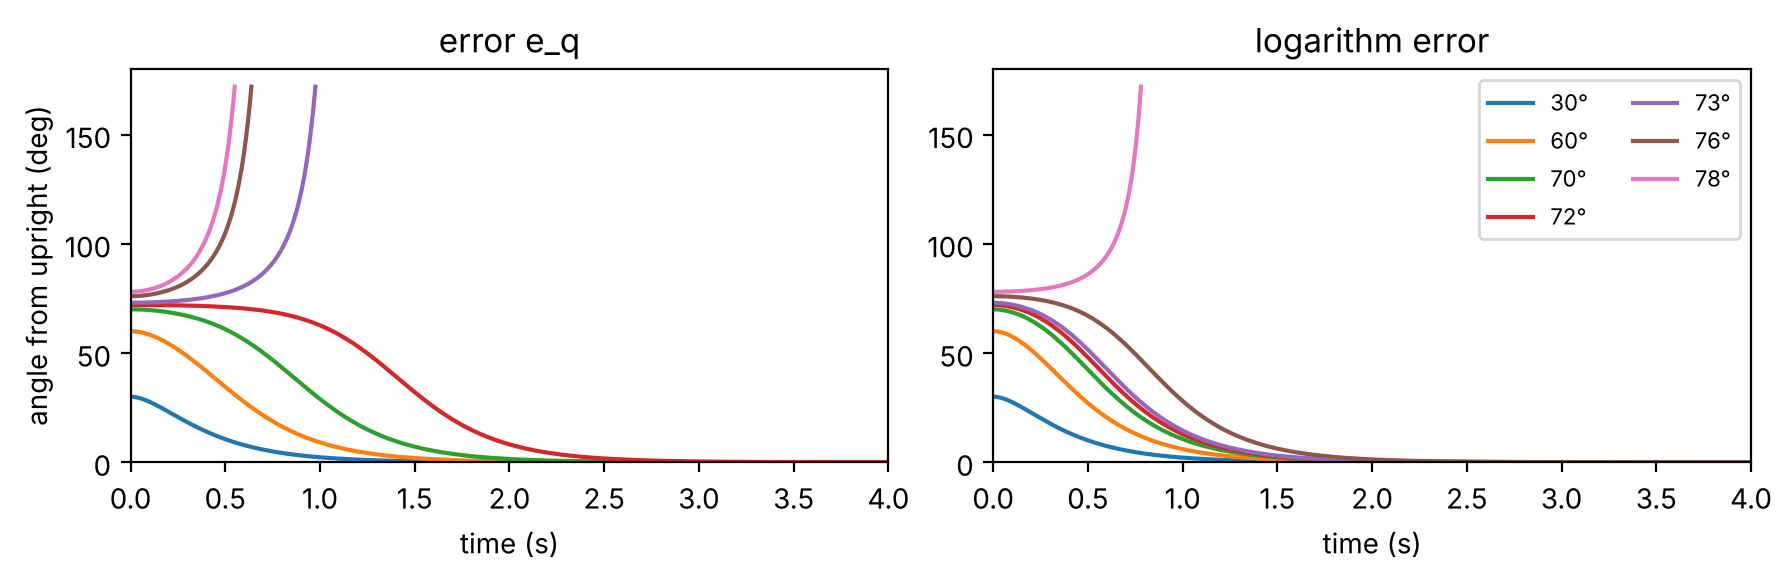

In [6]:
def pend_error(q, mode):
    e = np.cross(E3, q)
    if mode == "log":
        sn = np.linalg.norm(e)
        e = e * (np.arctan2(sn, q[2]) / sn if sn > 1e-9 else 1.0)
    return e


def pend_run(th0, mode="sin", T=8.0):
    q0 = np.array([np.sin(th0), 0, np.cos(th0)])
    hang = lambda t, x: x[2] + 0.99
    hang.terminal = True
    s = s2_sim(q0, Z3, lambda t, q, w: -K_pend @ np.r_[pend_error(q, mode), w], T, events=hang)
    tt = np.linspace(0, s.t[-1], 400)
    return tt, np.degrees(np.arccos(np.clip(s.sol(tt)[2], -1, 1)))


print(f"predicted boundary with e_q: {np.degrees(np.arccos(m * GRAV / kp)):.1f} deg")
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for k, mode in enumerate(("sin", "log")):
    for deg in (30, 60, 70, 72, 73, 76, 78):
        tt, ang = pend_run(np.radians(deg), mode)
        ax[k].plot(tt, ang, label=f"{deg}°")
    ax[k].set(title="error e_q" if mode == "sin" else "logarithm error", xlabel="time (s)", ylim=(0, 180), xlim=(0, 4))
ax[0].set_ylabel("angle from upright (deg)")
ax[1].legend(ncol=2, fontsize=8)
plt.tight_layout()

## 3. The rigid body: one gain for every attitude

$J\dot\Omega + \Omega\times J\Omega = \tau$ (set `mgrho` to add a pendulum's gravity torque). The linear state is $(\eta, \delta\Omega)$, with no constraint.

In [7]:
J = np.diag([0.03, 0.05, 0.07])
Ji = np.linalg.inv(J)
B_att = np.vstack([np.zeros((3, 3)), Ji])
Q_att, R_att = np.diag([100.0] * 3 + [1.0] * 3), 20.0 * I3


def so3_A(Rd, Od, mgrho=Z3):
    A = np.zeros((6, 6))
    A[:3, :3], A[:3, 3:] = -hat(Od), I3
    A[3:, :3] = -Ji @ hat(mgrho) @ hat(Rd.T @ E3)
    A[3:, 3:] = Ji @ (hat(J @ Od) - hat(Od) @ J)
    return A


def e_R(R, Rd):
    return 0.5 * vee(Rd.T @ R - R.T @ Rd)


def e_Omega(R, Rd, Om, Od):
    return Om - R.T @ Rd @ Od


def so3_sim(R0, O0, ctrl, T, t_eval, t0=0.0, max_step=np.inf):
    def rhs(t, x):
        R, Om = x[:9].reshape(3, 3), x[9:]
        return np.r_[(R @ hat(Om)).ravel(), Ji @ (np.cross(J @ Om, Om) + ctrl(t, R, Om))]
    return solve_ivp(rhs, [t0, T], np.r_[R0.ravel(), O0], t_eval=t_eval, rtol=1e-8, atol=1e-10, method="DOP853",
                     max_step=max_step)


P_hover = solve_continuous_are(so3_A(I3, Z3), B_att, Q_att, R_att)
K_hover = np.linalg.solve(R_att, B_att.T @ P_hover)
print(np.round(K_hover, 3))

[[2.236 0.    0.    0.429 0.    0.   ]
 [0.    2.236 0.    0.    0.523 0.   ]
 [0.    0.    2.236 0.    0.    0.603]]


### Against an Euler-angle LQR

Same plant, same weights, same initial error. The competitor linearizes in ZYX Euler angles about the target and feeds back wrapped angle differences. Change `pitch_deg` and watch.

pitch  0 deg, geometric: max error   20.0 deg, peak torque  0.76 N·m
pitch  0 deg, Euler    : max error   20.0 deg, peak torque  0.81 N·m


pitch 85 deg, geometric: max error   20.0 deg, peak torque  0.76 N·m
pitch 85 deg, Euler    : max error  177.8 deg, peak torque 14.22 N·m


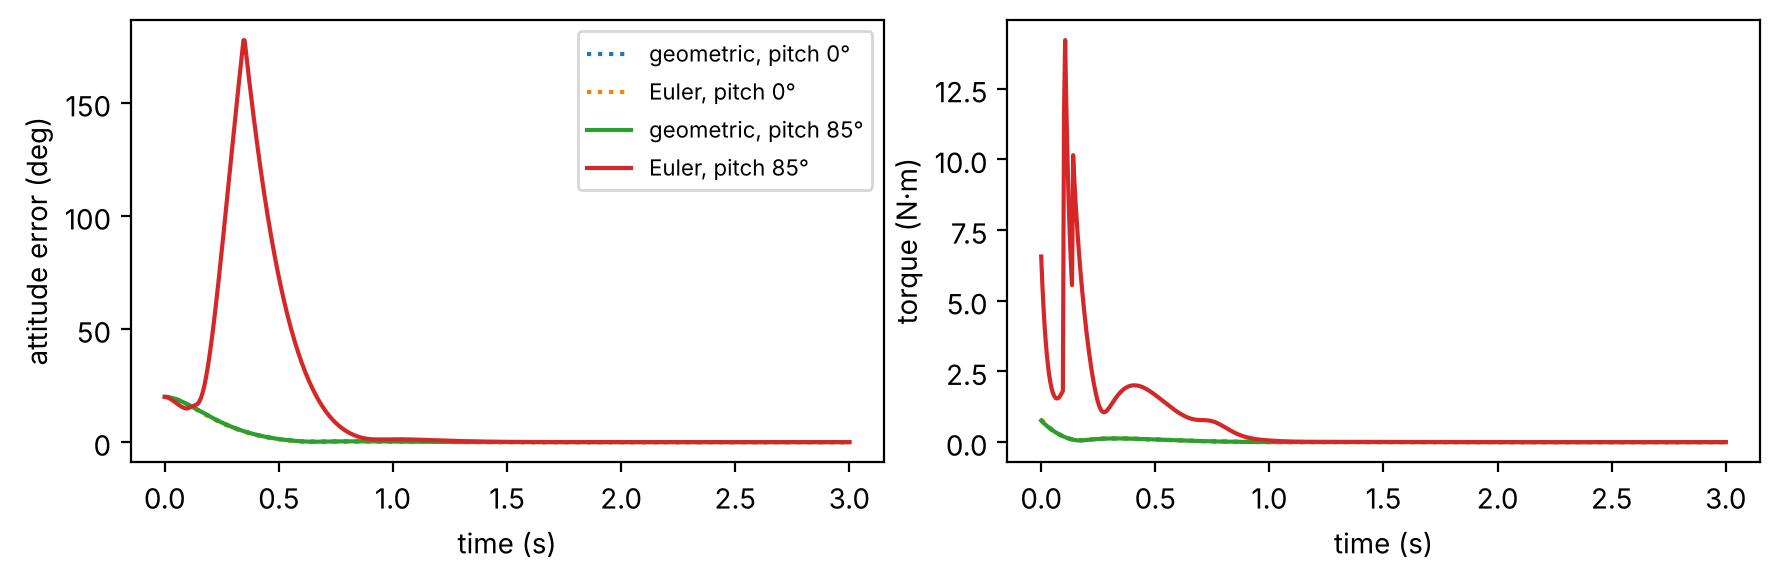

In [8]:
def Ry(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])


def euler_of(R):
    return np.array([np.arctan2(R[1, 0], R[0, 0]), -np.arcsin(np.clip(R[2, 0], -1, 1)), np.arctan2(R[2, 1], R[2, 2])])


def euler_E(th, ph):
    return np.array([[-np.sin(th), 0, 1], [np.cos(th) * np.sin(ph), np.cos(ph), 0], [np.cos(th) * np.cos(ph), -np.sin(ph), 0]])


def euler_f(x, tau):
    return np.r_[np.linalg.solve(euler_E(x[1], x[2]), x[3:]), Ji @ (np.cross(J @ x[3:], x[3:]) + tau)]


def euler_A(x, tau, h=1e-6):
    return np.column_stack([(euler_f(x + h * d, tau) - euler_f(x - h * d, tau)) / (2 * h) for d in np.eye(6)])


wrap = lambda a: (a + np.pi) % (2 * np.pi) - np.pi


def hold(pitch_deg, err_deg, axis=(1, 1, 1), T=3.0):
    Rd = Ry(np.radians(pitch_deg))
    eul_d = euler_of(Rd)
    KE = np.linalg.solve(R_att, B_att.T @ solve_continuous_are(euler_A(np.r_[eul_d, Z3], Z3), B_att, Q_att, R_att))
    R0 = Rd @ expm_so3(np.radians(err_deg) * np.array(axis) / np.linalg.norm(axis))
    laws = {"geometric": lambda t, R, Om: -K_hover @ np.r_[e_R(R, Rd), Om],
            "Euler": lambda t, R, Om: -KE @ np.r_[wrap(euler_of(R) - eul_d), Om]}
    out, te = {}, np.linspace(0, T, 601)
    for name, law in laws.items():
        s = so3_sim(R0, Z3, law, T, te, max_step=2e-3)
        Rs = s.y[:9].T.reshape(-1, 3, 3)
        out[name] = (s.t, np.array([np.degrees(np.linalg.norm(log_so3(Rd.T @ R))) for R in Rs]),
                     np.array([np.linalg.norm(law(t, R, x[9:])) for t, R, x in zip(s.t, Rs, s.y.T)]))
    return out


fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for pitch_deg, ls in ((0, ":"), (85, "-")):
    for name, (t, ang, tq) in hold(pitch_deg, 20).items():
        ax[0].plot(t, ang, ls, label=f"{name}, pitch {pitch_deg}°")
        ax[1].plot(t, tq, ls)
        print(f"pitch {pitch_deg:2d} deg, {name:9s}: max error {ang.max():6.1f} deg, peak torque {tq.max():5.2f} N·m")
ax[0].set(xlabel="time (s)", ylabel="attitude error (deg)")
ax[1].set(xlabel="time (s)", ylabel="torque (N·m)")
ax[0].legend(fontsize=8)
plt.tight_layout()

## 4. Tracking a flip

One full turn in 1.5 s about an axis 5° off the pitch axis. Evaluate $A(t)$ along the reference, integrate the Riccati equation backwards, and feed the gain $(e_R,\ e_\Omega + \Omega_d\times e_R)$.

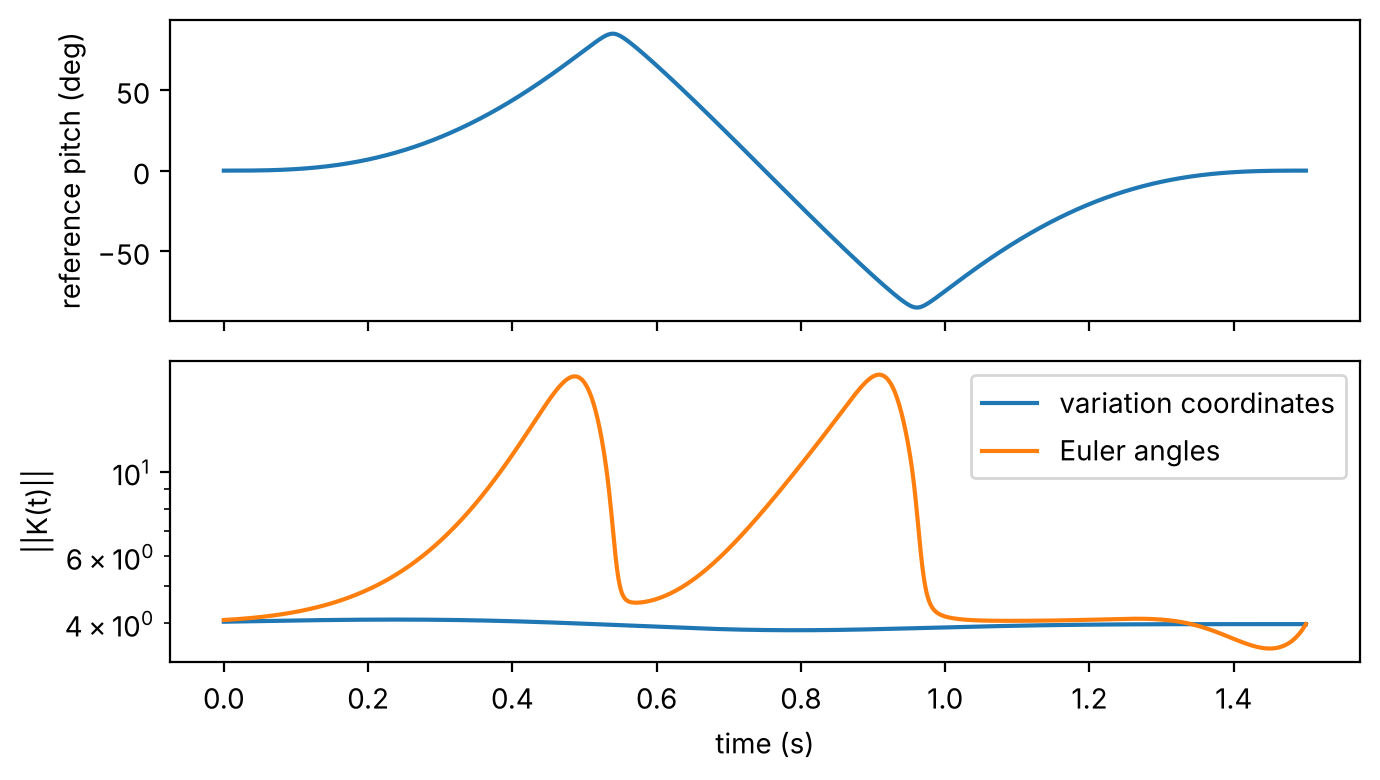

In [9]:
T_flip = 1.5
n_axis = np.array([np.sin(np.radians(5)), np.cos(np.radians(5)), 0.0])


def flip(t):
    s = np.clip(t / T_flip, 0, 1)
    a = 2 * np.pi * (10 * s**3 - 15 * s**4 + 6 * s**5)
    da = 2 * np.pi * (30 * s**2 - 60 * s**3 + 30 * s**4) / T_flip
    dda = 2 * np.pi * (60 * s - 180 * s**2 + 120 * s**3) / T_flip**2
    Od = da * n_axis
    return expm_so3(a * n_axis), Od, J @ (dda * n_axis) + np.cross(Od, J @ Od)


def riccati(Afun, Pf, T, n=1501):
    Rinv = np.linalg.inv(R_att)

    def rhs(t, pv):
        P, A = pv.reshape(6, 6), Afun(t)
        return -(A.T @ P + P @ A - P @ B_att @ Rinv @ B_att.T @ P + Q_att).ravel()

    ts = np.linspace(T, 0, n)
    sol = solve_ivp(rhs, [T, 0], Pf.ravel(), t_eval=ts, rtol=1e-9, atol=1e-11, method="LSODA")
    Ps = sol.y.T.reshape(-1, 6, 6)[::-1]
    return ts[::-1], Ps, np.array([Rinv @ B_att.T @ P for P in Ps])


tg = np.linspace(0, T_flip, 1501)
A_tab = interp1d(tg, np.array([so3_A(*flip(t)[:2]) for t in tg]), axis=0)
ts, Ps, Ks = riccati(lambda t: A_tab(t), P_hover, T_flip)
K_of_t = interp1d(ts, Ks, axis=0)

# the same design in Euler angles, for the gain plot
eul = np.array([euler_of(flip(t)[0]) for t in tg])
eul[:, 0], eul[:, 2] = np.unwrap(eul[:, 0]), np.unwrap(eul[:, 2])
AE_tab = interp1d(tg, np.array([euler_A(np.r_[e, flip(t)[1]], flip(t)[2]) for e, t in zip(eul, tg)]), axis=0)
_, _, KsE = riccati(lambda t: AE_tab(t), P_hover, T_flip)

fig, ax = plt.subplots(2, 1, figsize=(7, 4), sharex=True)
ax[0].plot(tg, np.degrees(eul[:, 1]))
ax[0].set_ylabel("reference pitch (deg)")
ax[1].semilogy(ts, np.linalg.norm(Ks, axis=(1, 2)), label="variation coordinates")
ax[1].semilogy(ts, np.linalg.norm(KsE, axis=(1, 2)), label="Euler angles")
ax[1].set(xlabel="time (s)", ylabel="||K(t)||")
ax[1].legend()
plt.tight_layout()

final tracking error 0.0070 deg


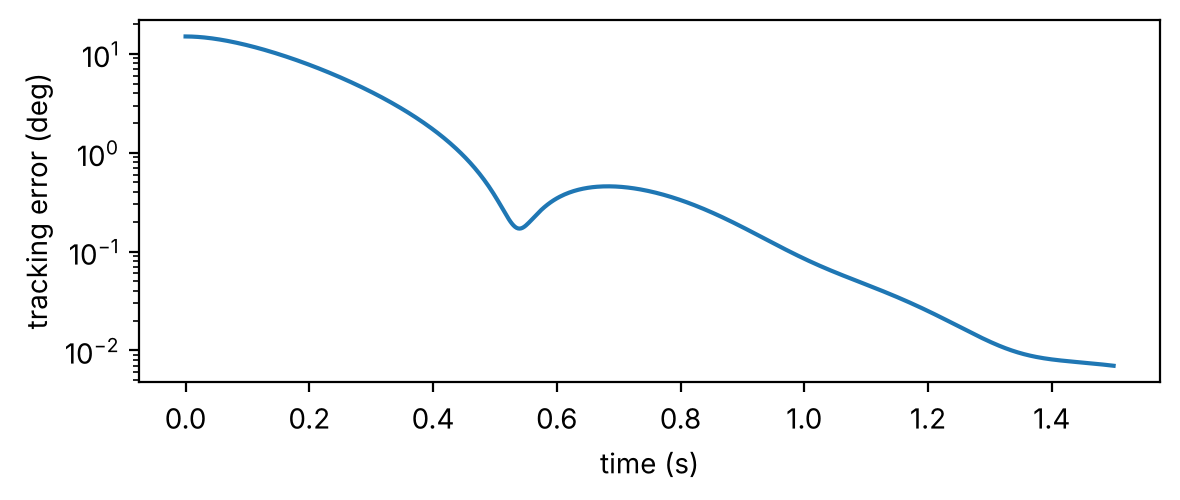

In [10]:
def flip_law(velocity="transported"):
    def law(t, R, Om):
        t = min(max(t, 0.0), T_flip)
        Rd, Od, tau_d = flip(t)
        e_R_val, eO = e_R(R, Rd), e_Omega(R, Rd, Om, Od)
        s = np.r_[e_R_val, eO + np.cross(Od, e_R_val)] if velocity == "transported" else np.r_[e_R_val, eO]
        return tau_d - K_of_t(t) @ s
    return law


axis = np.array([1.0, 0.5, -0.7])
axis /= np.linalg.norm(axis)
te = np.linspace(0, T_flip, 601)
s = so3_sim(expm_so3(np.radians(15) * axis), Z3, flip_law(), T_flip, te)
err = [np.degrees(np.linalg.norm(log_so3(flip(t)[0].T @ x[:9].reshape(3, 3)))) for t, x in zip(s.t, s.y.T)]
plt.figure(figsize=(6, 2.6))
plt.semilogy(s.t, err)
plt.xlabel("time (s)")
plt.ylabel("tracking error (deg)")
plt.tight_layout()
print(f"final tracking error {err[-1]:.4f} deg")

### A sharp test of the state dictionary

For small errors the closed-loop cost must equal $s_0^\top P(t_0)\,s_0$. Inject an attitude error mid-flip, where $\Omega_d$ is large, and compare. Feeding the gain $(e_R, e_\Omega)$ instead of $(e_R, e_\Omega + \Omega_d\times e_R)$ gives a stable loop with twice the cost: to first order $e_\Omega$ is $\dot\eta$, not $\delta\Omega$.

In [11]:
def flip_cost(law, eta0, t0):
    Rd0, Od0, _ = flip(t0)

    def rhs(t, x):
        R, Om = x[:9].reshape(3, 3), x[9:12]
        Rd, Od, tau_d = flip(t)
        tau = law(t, R, Om)
        sv, du = np.r_[log_so3(Rd.T @ R), Om - Od], tau - tau_d
        return np.r_[(R @ hat(Om)).ravel(), Ji @ (np.cross(J @ Om, Om) + tau), sv @ Q_att @ sv + du @ R_att @ du]

    x = solve_ivp(rhs, [t0, T_flip], np.r_[(Rd0 @ expm_so3(eta0)).ravel(), Od0, 0.0], rtol=1e-9, atol=1e-13,
                  method="DOP853").y[:, -1]
    RdT, OdT, _ = flip(T_flip)
    sT = np.r_[log_so3(RdT.T @ x[:9].reshape(3, 3)), x[9:12] - OdT]
    return x[12] + sT @ P_hover @ sT


t0 = 0.45
P0 = Ps[np.argmin(np.abs(ts - t0))]
for deg in (1, 15, 45):
    eta0 = np.radians(deg) * axis
    pred = eta0 @ P0[:3, :3] @ eta0
    print(f"{deg:2d} deg:  cost / prediction = {flip_cost(flip_law(), eta0, t0) / pred:.4f} (transported), "
          f"{flip_cost(flip_law('naive'), eta0, t0) / pred:.4f} (e_Omega alone)")

 1 deg:  cost / prediction = 1.0000 (transported), 1.9974 (e_Omega alone)


15 deg:  cost / prediction = 1.0061 (transported), 2.0487 (e_Omega alone)


45 deg:  cost / prediction = 1.0638 (transported), 2.1378 (e_Omega alone)


## Starting points for the exercises

- **Exercise 7.2.** Build $B(t) = e^{At}b$ for a $2\times2$ matrix $A$ and compare the ranks of $[B,\ \dot B - AB]$ and $[B,\ \dot B + AB]$.
- **Exercise 7.4.** Call `hold(pitch_deg, err_deg)` over a grid of pitches and errors and record the peak torque of both loops.
- **Exercise 7.5.** Add `np.clip` on the force in `pend_run` and repeat the sweep of initial angles.
- Replace `e_R` by `log_so3(Rd.T @ R)` in `hold` and start 179° away: compare the time to recover.

In [12]:
out = hold(80, 10)
print({name: round(float(tq.max()), 2) for name, (t, ang, tq) in out.items()})

{'geometric': 0.39, 'Euler': 3.1}
